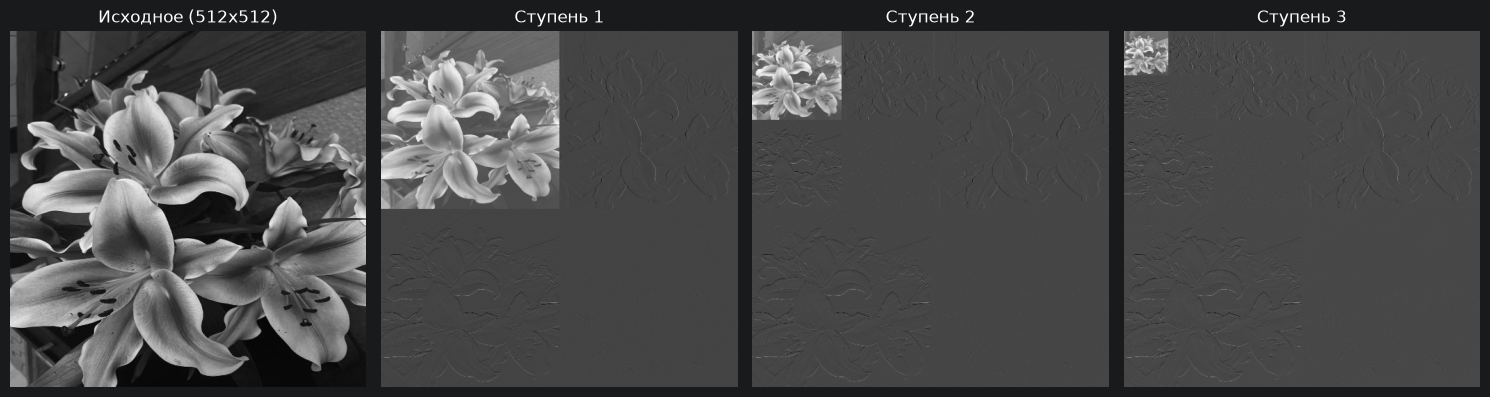

In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

image = cv.imread('img1.jpg')
image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
image = image.astype(np.float64)
image = cv.resize(image, (512, 512))

# 2. Функции для преобразования Хаара
def haar_transform_horizontal(image_data):
    even_cols = image_data[:, 0::2]
    odd_cols = image_data[:, 1::2]
    low_pass = (even_cols + odd_cols) / 2
    high_pass = (even_cols - odd_cols) / 2
    return np.concatenate([low_pass, high_pass], axis=1)

def haar_wavelet_2d(src):
    horizontal_pass = haar_transform_horizontal(src)
    return haar_transform_horizontal(horizontal_pass.T).T

# Первая ступень
wavelet_stage1 = haar_wavelet_2d(image)

# Вторая ступень (256x256)
wavelet_stage2 = wavelet_stage1.copy()
wavelet_stage2[:256, :256] = haar_wavelet_2d(wavelet_stage1[:256, :256])

# Третья ступень (128x128)
wavelet_stage3 = wavelet_stage2.copy()
wavelet_stage3[:128, :128] = haar_wavelet_2d(wavelet_stage2[:128, :128])

# 4. Нормализация для визуализации
def normalize(arr):
    arr_min, arr_max = arr.min(), arr.max()
    return np.uint8((arr - arr_min) / (arr_max - arr_min) * 255)

# 5. Визуализация
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(image, cmap="gray")
plt.title("Исходное (512x512)")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(normalize(wavelet_stage1), cmap="gray")
plt.title("Ступень 1")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(normalize(wavelet_stage2), cmap="gray")
plt.title("Ступень 2")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(normalize(wavelet_stage3), cmap="gray")
plt.title("Ступень 3")
plt.axis("off")

plt.tight_layout()
plt.show()
